```{eval-rst}
:download:`Download notebook <compilation.ipynb>`
```

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


# Capture, compilation and fixed loops

`compile_model` captures a one-pytree callable. For a Caskade module that input
is usually its packed parameter tensor:

This example uses a stock 64 x 64 float64 Caustics image simulator. Native calls compute the reference image and all 21 gradients before device assignment. The source uses `cuda:1` when two devices are visible; a fallback run checks only the available single device. Capture operates directly on the placed simulator. An already enabled backend is outside this capture interface.

In [1]:
%matplotlib inline
from collections import Counter

import caskade
import caustics
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import PowerNorm

import niagara as ng
from examples.niagara_examples.caustics import image_problem

visible_devices = torch.cuda.device_count()
home = torch.device("cuda:0" if visible_devices else "cpu")
source_home = torch.device("cuda:1" if visible_devices >= 2 else home)
problem = image_problem(64, device=home, dtype=torch.float64)
sim, params = problem.model, problem.truth.detach()
native_class = type(sim)
parameter_vectors = [params * (1.0 + fraction) for fraction in (-0.001, 0.0, 0.001)]
native_images = [sim(vector).detach().cpu() for vector in parameter_vectors]
reference = native_images[1]
q_native = params.clone().requires_grad_()
native_loss = sim(q_native).square().sum()
native_value = native_loss.detach().cpu()
native_gradient = torch.autograd.grad(native_loss, q_native)[0].detach().cpu()
del q_native, native_loss

print(
    {
        "niagara": ng.__version__,
        "caskade": caskade.__version__,
        "caustics": caustics.__version__,
        "torch": str(torch.__version__),
    }
)
print("Visible CUDA devices:", visible_devices)
if visible_devices < 2:
    print("Two-GPU placement is unavailable; this run uses one available device.")
placement = ng.assign_devices(sim, ng.DevicePlan(default=home, modules={"source": source_home}))
compiled = ng.compile_model(sim, params, record_scopes=True)
image = compiled(params)
assert image.device == home and sim.source.Re.device == source_home
torch.testing.assert_close(image.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
plan = compiled.execution_plan()
tensor_devices = Counter(node["device"] for node in plan["nodes"] if node["device"])
assert str(home) in tensor_devices and str(source_home) in tensor_devices
print("Selected backend:", compiled.backend)
print("Image shape/device:", tuple(image.shape), image.device)
print("Captured operations:", len(plan["nodes"]))
print("Captured tensor device labels:", dict(tensor_devices))

{'niagara': '0.7.0', 'caskade': '1.1.5', 'caustics': '1.7.1', 'torch': '2.12.0+cu126'}
Visible CUDA devices: 2


Selected backend: cuda_graph
Image shape/device: (64, 64) cuda:0
Captured operations: 210
Captured tensor device labels: {'cuda:0': 153, 'cuda:1': 54, 'cpu': 2}


The simulator outputs share an intensity scale and square-root display stretch. This notebook makes no performance inference from cold-call timings.

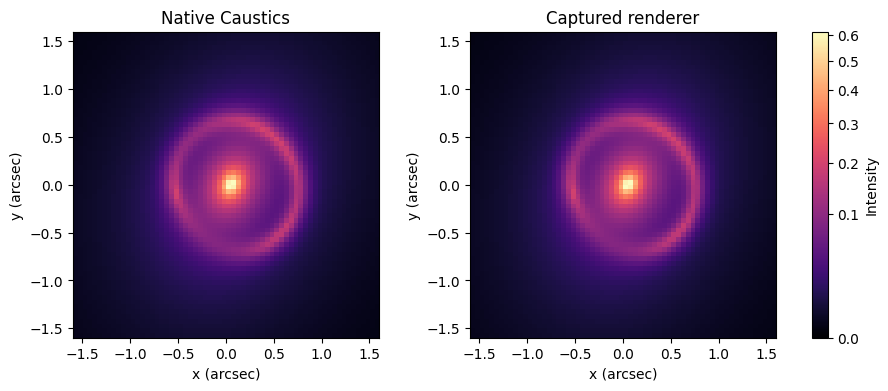

Maximum image absolute difference: 3.885780586188048e-16


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
norm = PowerNorm(0.5, vmin=0, vmax=float(reference.max()))
for ax, data, title in zip(
    axes,
    (reference.numpy(), image.detach().cpu().numpy()),
    ("Native Caustics", "Captured renderer"),
    strict=True,
):
    artist = ax.imshow(data, origin="lower", extent=(-1.6, 1.6, -1.6, 1.6), cmap="magma", norm=norm)
    ax.set(title=title, xlabel="x (arcsec)", ylabel="y (arcsec)")
fig.colorbar(artist, ax=axes, label="Intensity")
plt.show()
print("Maximum image absolute difference:", float((image.detach().cpu() - reference).abs().max()))

Bind additional fixed call arguments in a callable, or use `method=` for a named
module method. State guards are automatic for a module or bound module method.
For arbitrary closures, keep external captured state fixed. Niagara's
inspection cannot find every captured dependency.

## What preparation does

1. Trace tensor operations with FX while ordinary Caskade parameter handling runs.
2. Reject input mutation and unsupported local grad/inference/autocast changes.
3. Fold pure input-independent tensor work while retaining random operators.
4. Prepare state/input/mode guards and the selected tensor backend.
5. For CUDA replay, warm and capture fixed buffers before production calls.

Preparation can cost much more than one eager call. Record that cost
separately and reuse the program long enough to recover it.

## Backend selection

| Selection | Behavior |
| --- | --- |
| `auto`, CUDA inputs without ordinary AD history | Local or segmented CUDA replay when the tensor program is CUDA-only |
| `auto`, ordinary CUDA autograd | Inductor when Triton is available; otherwise TorchScript |
| `auto`, CPU | TorchScript |
| `eager` | Execute the captured FX tensor program without a numerical compiler |
| `torchscript` | Compatibility tensor-program tracing |
| `inductor`, `aot_eager` | Explicit Torch compiler backend |
| `cuda_graph` | Explicit local/segmented replay under its fixed-buffer restrictions |

CUDA replay does not build an ordinary autograd tape. Inputs and captured
constants must not require ordinary gradients. To replay a derivative, capture
that derivative as explicit tensor outputs using a transform first. A trainable
captured constant stays on the ordinary AD path; it is never silently frozen.

Local kernels are fused with Inductor when available. Without Triton, replay
uses the TorchScript tensor fallback. Scalar flags and empty keyword containers
are static metadata; only tensor leaves are passed to that fallback's tracer.

## Validate ordinary and explicit gradients

The native image loss and its full 21-component gradient were saved before placement. The first comparison uses an ordinary autograd specialization. The second transforms the pure graph into explicit gradient/value outputs, then selects the final backend. Both comparisons check every component.

In [3]:
ordinary_input = params.clone().requires_grad_()
ordinary = ng.compile_model(sim, ordinary_input)
ordinary_image = ordinary(ordinary_input)
ordinary_loss = ordinary_image.square().sum()
ordinary_gradient = torch.autograd.grad(ordinary_loss, ordinary_input)[0]
assert ordinary_gradient.device == home and ordinary_gradient.numel() == 21
ordinary_actual = ordinary_gradient.detach().cpu()
torch.testing.assert_close(ordinary_actual, native_gradient, atol=1e-9, rtol=1e-8)

loss_program = compiled.transform(
    lambda render: lambda p: render(p).square().sum(), params, backend="eager"
)
derivative = loss_program.transform(torch.func.grad_and_value, params, backend="auto")
explicit_gradient, value = derivative(params)
assert explicit_gradient.device == home and explicit_gradient.numel() == 21
explicit_actual = explicit_gradient.detach().cpu()
torch.testing.assert_close(explicit_actual, native_gradient, atol=1e-9, rtol=1e-8)
torch.testing.assert_close(value.detach().cpu(), native_value, atol=1e-10, rtol=1e-9)
print("Ordinary-autograd backend:", ordinary.backend)
print("Explicit derivative backend:", derivative.backend)
print("All 21 ordinary and explicit gradient components agree.")
absolute = (explicit_actual - native_gradient).abs()
worst = int(absolute.argmax())
print(
    "Maximum explicit-gradient absolute difference:",
    float(absolute.max()),
    "at",
    problem.names[worst],
)
print("Reference at that component:", float(native_gradient[worst]))
print(
    "Relative L2 difference:",
    float(
        torch.linalg.vector_norm(explicit_actual - native_gradient)
        / torch.linalg.vector_norm(native_gradient).clamp_min(
            torch.finfo(native_gradient.dtype).eps
        )
    ),
)
print(f"{'Parameter':20s} {'Native':>12s} {'Ordinary':>12s} {'Explicit':>12s} {'Abs error':>12s}")
for name, native, first, second, error in zip(
    problem.names,
    native_gradient.tolist(),
    ordinary_actual.tolist(),
    explicit_actual.tolist(),
    absolute.tolist(),
    strict=True,
):
    print(f"{name:20s} {native:12.4e} {first:12.4e} {second:12.4e} {error:12.4e}")
del ordinary_input, ordinary_image, ordinary_loss, ordinary_gradient

G:\Qsync\Maitrise\Projects\Niagara\.venv\Lib\site-packages\torch\autograd\graph.py:882: UserWarning: The AccumulateGrad node's stream does not match the stream of the node that produced the incoming gradient. This may incur unnecessary synchronization and break CUDA graph capture if the AccumulateGrad node's stream is the default stream. This mismatch is caused by an AccumulateGrad node created prior to the current iteration being kept alive. This can happen if the autograd graph is still being kept alive by tensors such as the loss, or if you are using DDP, which will stash a reference to the node. To resolve the mismatch, delete all references to the autograd graph or ensure that DDP initialization is performed under the same stream as subsequent forwards. If the mismatch is intentional, you can use torch.autograd.graph.set_warn_on_accumulate_grad_stream_mismatch(False) to suppress this warning. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\inpu

Ordinary-autograd backend: inductor
Explicit derivative backend: cuda_graph
All 21 ordinary and explicit gradient components agree.
Maximum explicit-gradient absolute difference: 1.7763568394002505e-14 at shear.gamma_1
Reference at that component: -2.2773892452733593
Relative L2 difference: 6.714375442505725e-17
Parameter                  Native     Ordinary     Explicit    Abs error
mass.x0                3.6196e+01   3.6196e+01   3.6196e+01   1.4211e-14
mass.y0               -1.4890e+01  -1.4890e+01  -1.4890e+01   3.5527e-15
mass.q                -4.0049e-01  -4.0049e-01  -4.0049e-01   3.1641e-15
mass.phi              -4.1763e-01  -4.1763e-01  -4.1763e-01   7.2164e-16
mass.Rein             -4.9576e-01  -4.9576e-01  -4.9576e-01   7.7716e-15
shear.gamma_1         -2.2774e+00  -2.2774e+00  -2.2774e+00   1.7764e-14
shear.gamma_2          5.6712e+00   5.6712e+00   5.6712e+00   1.3323e-14
source.x0             -3.6085e+01  -3.6085e+01  -3.6085e+01   1.4211e-14
source.y0              1.6891

## Guarded metadata and state

Input pytrees, shapes, strides, dtypes, devices, requires-grad status, layouts
and execution modes specialize a program. Model guards track known tensor
versions/metadata and mutable list/dictionary state, as well as field and node
identity. Replacing an immutable tuple requires recapture even if its values
compare equal. Internals of opaque objects are not inspected recursively.

When a guard fails, validate the changed configuration and prepare a new
program. Data-dependent Python branches, arbitrary mutation and some Torch
modifiers fall outside automatic validation.

In [4]:
try:
    compiled(params[1:])
except ng.GuardError as error:
    print("Expected metadata rejection:", error)
else:
    raise AssertionError("A changed parameter shape must not execute the prepared program")

Expected metadata rejection: Input tree, shape, stride, dtype, device, or requires_grad changed; recapture


In [5]:
with compiled.session():
    images = [compiled(vector) for vector in parameter_vectors]
for index, (actual, expected) in enumerate(zip(images, native_images, strict=True)):
    torch.testing.assert_close(actual.detach().cpu(), expected, atol=1e-10, rtol=1e-9)
    error = float((actual.detach().cpu() - expected).abs().max())
    print(
        f"Parameter vector {index}: shape={tuple(actual.shape)}, device={actual.device}, max absolute difference={error:.3g}"
    )
print("Three parameter vectors agree with native Caustics.")

Parameter vector 0: shape=(64, 64), device=cuda:0, max absolute difference=4.16e-16
Parameter vector 1: shape=(64, 64), device=cuda:0, max absolute difference=3.89e-16
Parameter vector 2: shape=(64, 64), device=cuda:0, max absolute difference=3.89e-16
Three parameter vectors agree with native Caustics.


A session checks model state around a fixed loop while each call still checks
its inputs and execution mode. Exit checks detect changed model state. A
session provides no concurrency lock; compiled objects support one caller at a time.

## Graph access

`compiled.graph` is the pure captured tensor program used for controlled
composition and transforms. Calling it directly bypasses wrapper guards and
compiler selection. Use it inside a larger prepared transition when you control state and
metadata, as in the MCMC example. For general calls, the wrapper supplies the
state and metadata checks.

`execution_plan()` describes captured dependencies, scopes and tensor devices.
Its dependency levels are not measured durations or evidence of simultaneous
GPU execution.

## Release prepared work and restore native calls

Discard prepared objects before changing placement. Closing the split routing leaves tensors on their current homes. A new uniform plan co-locates them for the final native call.

In [6]:
del ordinary, derivative, loss_program, compiled, images
placement.close()
uniform = ng.assign_devices(sim, ng.DevicePlan(default=home))
uniform.close()
restored = sim(params)
assert type(sim) is native_class and sim.source.Re.device == home
torch.testing.assert_close(restored.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
print("Native class restored:", type(sim).__name__, "source home:", sim.source.Re.device)

Native class restored: LensSource source home: cuda:0
